In [12]:
import sys, ctypes, platform
from importlib.metadata import version, PackageNotFoundError

print("Python:", sys.version.split()[0], "|", platform.machine())

for pkg in ["tensorflow", "tensorflow-intel", "numpy", "keras"]:
    try:
        print(f"{pkg}:", version(pkg))
    except PackageNotFoundError:
        print(f"{pkg}: not installed")

k32 = ctypes.windll.kernel32
print("AVX  supported:", bool(k32.IsProcessorFeaturePresent(39)))
print("AVX2 supported:", bool(k32.IsProcessorFeaturePresent(40)))

Python: 3.11.15 | AMD64
tensorflow: 2.15.0
tensorflow-intel: 2.15.0
numpy: 1.26.4
keras: 2.15.0
AVX  supported: True
AVX2 supported: True


In [13]:
import winreg

try:
    key = winreg.OpenKey(
        winreg.HKEY_LOCAL_MACHINE,
        r"SOFTWARE\Microsoft\VisualStudio\14.0\VC\Runtimes\x64",
    )
    installed, _ = winreg.QueryValueEx(key, "Installed")
    version, _ = winreg.QueryValueEx(key, "Version")
    print("Installed:", bool(installed), "| Version:", version)
except FileNotFoundError:
    print("Visual C++ 2015-2022 x64 runtime is NOT installed")

Installed: True | Version: v14.51.36247.00


In [14]:
import tensorflow as tf
print(tf.__version__)

2.15.0


In [15]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Bidirectional, Dense, Dropout, LSTM
from tensorflow.keras.models import Sequential

# 1. قراءة الملفات مع إضافة حرف r لتجنب مشكلة مسارات ويندوز
path_prefix = Path(r"D:\Learning\NTI-HireReady AI in DA\TECHNICAL\NASA_PROJECT")

index_names = ["unit_number", "time_cycle"]
setting_names = ["altitude_setting", "mach_setting", "throttle_resolver_setting"]
sensor_names = [
    "fan_inlet_temp",
    "LPC_outlet_temp",
    "HPC_outlet_temp",
    "LPT_outlet_temp",
    "fan_inlet_pressure",
    "bypass_duct_pressure",
    "HPC_outlet_pressure",
    "physical_fan_speed",
    "physical_core_speed",
    "engine_pressure_ratio",
    "HPC_static_pressure",
    "fuel_flow_ratio",
    "corrected_fan_speed",
    "corrected_core_speed",
    "bypass_ratio",
    "burner_fuel_air_ratio",
    "bleed_enthalpy",
    "demanded_fan_speed",
    "demanded_corrected_fan_speed",
    "HPT_coolant_bleed",
    "LPT_coolant_bleed",
]
col_names = index_names + setting_names + sensor_names

# Quick check: show what's in the folder if a file is missing
for f in ["train_FD001.txt", "test_FD001.txt", "RUL_FD001.txt"]:
    if not (path_prefix / f).exists():
        print(f"Missing: {path_prefix / f}")
        print("Files in folder:", [p.name for p in path_prefix.iterdir()])
        raise FileNotFoundError(f)

train_df = pd.read_csv(
    path_prefix / "train_FD001.txt", sep=r"\s+", header=None, names=col_names
)
test_df = pd.read_csv(
    path_prefix / "test_FD001.txt", sep=r"\s+", header=None, names=col_names
)
true_rul = pd.read_csv(
    path_prefix / "RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"]
)

print(f"Dataset Shape: {train_df.shape}")
train_df.head()

Dataset Shape: (20631, 26)


,unit_number,time_cycle,altitude_setting,mach_setting,throttle_resolver_setting,fan_inlet_temp,LPC_outlet_temp,HPC_outlet_temp,LPT_outlet_temp,fan_inlet_pressure,...,fuel_flow_ratio,corrected_fan_speed,corrected_core_speed,bypass_ratio,burner_fuel_air_ratio,bleed_enthalpy,demanded_fan_speed,demanded_corrected_fan_speed,HPT_coolant_bleed,LPT_coolant_bleed
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [16]:
# حساب الـ RUL
def compute_rul(df):
  max_cycles = df.groupby("unit_number")["time_cycle"].max()
  merged = df.merge(max_cycles.rename("max_cycle"), on="unit_number")
  df["RUL"] = merged["max_cycle"] - merged["time_cycle"]
  return df


train_df = compute_rul(train_df)

print("Sample with Calculated RUL:")
train_df[["unit_number", "time_cycle", "RUL"]].head()


Sample with Calculated RUL:


,unit_number,time_cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


In [17]:
# Generate comprehensive descriptive statistics
stats_summary = train_df.describe().T[
    ["mean", "std", "min", "50%", "max"]
]
stats_summary.rename(columns={"50%": "median"}, inplace=True)

print("Statistical Summary of Sensors and Settings:")
display(stats_summary.head(10))

Statistical Summary of Sensors and Settings:


,mean,std,min,median,max
unit_number,51.506568,2.922763e+01,1.0000,52.00,100.0000
time_cycle,108.807862,6.888099e+01,1.0000,104.00,362.0000
altitude_setting,-0.000009,2.187313e-03,-0.0087,0.00,0.0087
mach_setting,0.000002,2.930621e-04,-0.0006,0.00,0.0006
throttle_resolver_setting,100.000000,0.000000e+00,100.0000,100.00,100.0000
fan_inlet_temp,518.670000,0.000000e+00,518.6700,518.67,518.6700
LPC_outlet_temp,642.680934,5.000533e-01,641.2100,642.64,644.5300
HPC_outlet_temp,1590.523119,6.131150e+00,1571.0400,1590.10,1616.9100
LPT_outlet_temp,1408.933782,9.000605e+00,1382.2500,1408.04,1441.4900
fan_inlet_pressure,14.620000,1.776400e-15,14.6200,14.62,14.6200


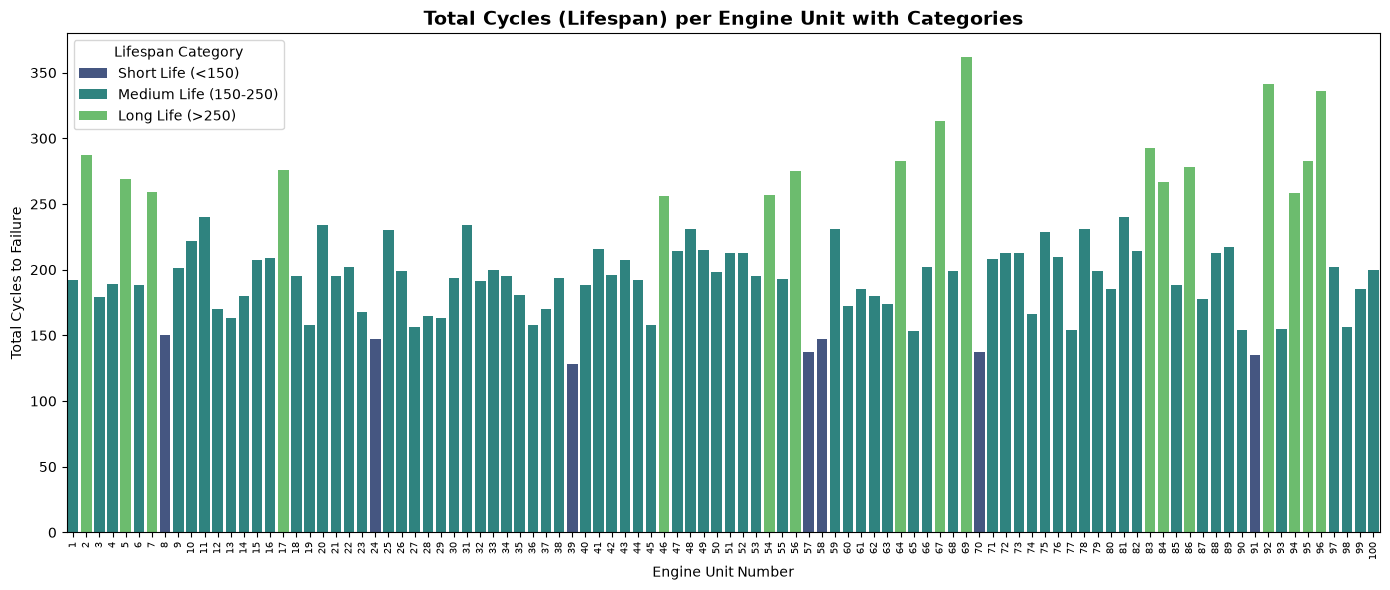

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# حساب أقصى عدد دورات لكل محرك
max_cycles = (
    train_df.groupby("unit_number")["time_cycle"].max().reset_index()
)
max_cycles.rename(columns={"time_cycle": "total_cycles"}, inplace=True)

# تقسيم المحركات إلى فئات بناءً على إجمالي العمر
max_cycles["lifespan_category"] = pd.cut(
    max_cycles["total_cycles"],
    bins=[0, 150, 250, 400],
    labels=["Short Life (<150)", "Medium Life (150-250)", "Long Life (>250)"],
)

# رسم الأعمدة الملونة حسب الفئة
plt.figure(figsize=(14, 6))
sns.barplot(
    x="unit_number",
    y="total_cycles",
    hue="lifespan_category",
    data=max_cycles,
    dodge=False,
    palette="viridis",
)
plt.title(
    "Total Cycles (Lifespan) per Engine Unit with Categories",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Engine Unit Number")
plt.ylabel("Total Cycles to Failure")
plt.xticks(rotation=90, fontsize=7)
plt.legend(title="Lifespan Category")
plt.tight_layout()
plt.show()

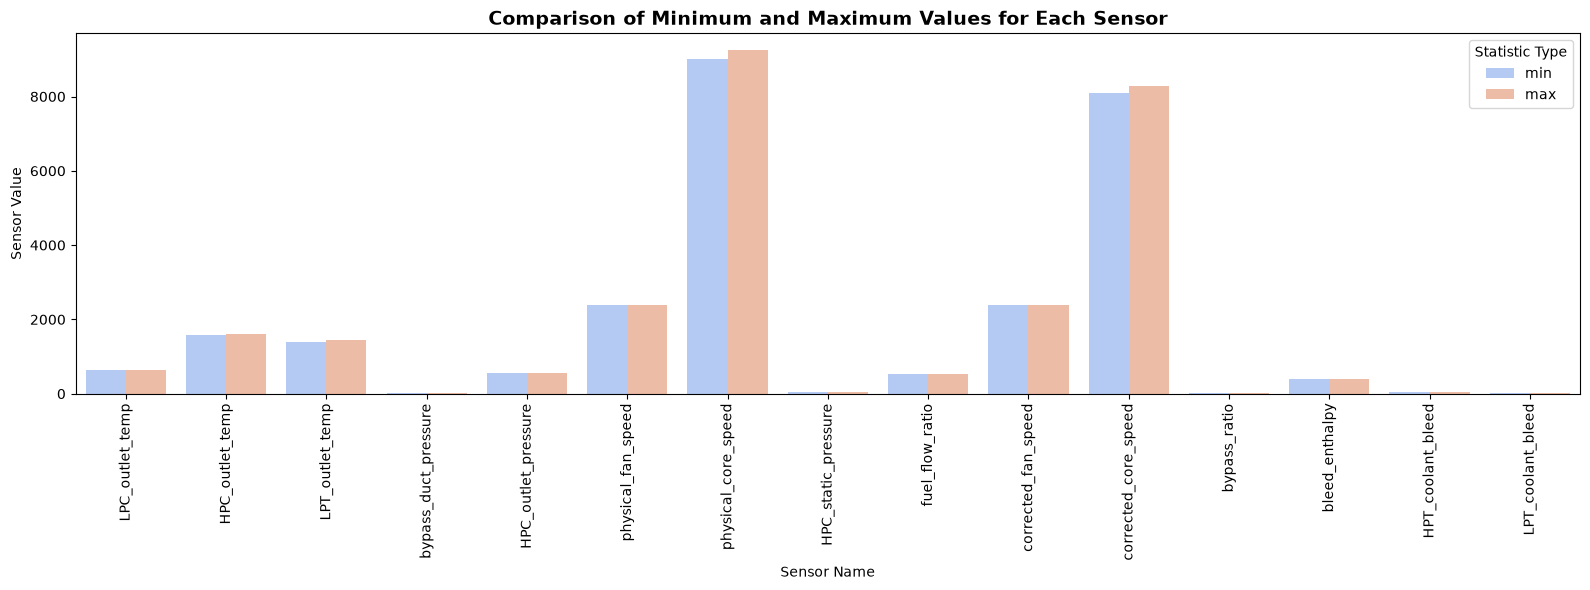

In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# استبعاد الأعمدة غير الخاصة بالحساسات تلقائياً
exclude_cols = [
    "unit_number",
    "time_cycle",
    "RUL",
    "lifespan_category",
    "altitude_setting",
    "mach_setting",
    "throttle_resolver_setting",
]
available_sensors = [
    col
    for col in train_df.columns
    if col not in exclude_cols and train_df[col].nunique() > 1
]

# تجميع الحد الأدنى والحد الأقصى لكل حساس في جدول واحد
sensor_stats = pd.DataFrame(
    {"min": train_df[available_sensors].min(), "max": train_df[available_sensors].max()}
).reset_index()
sensor_stats.rename(columns={"index": "sensor_name"}, inplace=True)

# إعادة تشكيل الجدول ليلائم العرض المزدوج في seaborn
sensor_melted = sensor_stats.melt(
    id_vars="sensor_name",
    value_vars=["min", "max"],
    var_name="stat_type",
    value_name="value",
)

# رسم الأعمدة المزدوجة لكل حساس
plt.figure(figsize=(16, 6))
sns.barplot(
    x="sensor_name",
    y="value",
    hue="stat_type",
    data=sensor_melted,
    palette="coolwarm",
)
plt.title(
    "Comparison of Minimum and Maximum Values for Each Sensor",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Sensor Name")
plt.ylabel("Sensor Value")
plt.xticks(rotation=90)
plt.legend(title="Statistic Type")
plt.tight_layout()
plt.show()

In [20]:
# استبعاد الأعمدة الثابتة
exclude_cols = [
    "unit_number",
    "time_cycle",
    "RUL",
    "altitude_setting",
    "mach_setting",
    "throttle_resolver_setting",
]
base_feature_cols = [
    col for col in train_df.columns if col not in exclude_cols
]

# 2. هندسة الميزات المحسّنة: إضافة Rolling Mean + Rolling Std
window_size = 15
for df in [train_df, test_df]:
  for col in base_feature_cols:
    df[f"{col}_mean"] = (
        df.groupby("unit_number")[col]
        .transform(lambda x: x.rolling(window=window_size, min_periods=1).mean())
    )
    df[f"{col}_std"] = (
        df.groupby("unit_number")[col]
        .transform(lambda x: x.rolling(window=window_size, min_periods=1).std())
        .fillna(0)
    )

feature_cols = [
    col for col in train_df.columns if col not in exclude_cols + ["RUL"]
]


In [21]:
# 3. تطبيق الـ Clipping للعمر المتبقي
max_rul = 125
train_df["RUL"] = train_df["RUL"].clip(upper=max_rul)

train_engines = list(range(1, 81))
val_engines = list(range(81, 101))

train_data = train_df[train_df["unit_number"].isin(train_engines)]
val_data = train_df[train_df["unit_number"].isin(val_engines)].copy()
val_data["RUL"] = val_data["RUL"].clip(upper=max_rul)

# 4. توحيد النطاق (Scaling)
scaler = MinMaxScaler()
train_data_scaled = train_data.copy()
val_data_scaled = val_data.copy()
test_data_scaled = test_df.copy()

train_data_scaled[feature_cols] = scaler.fit_transform(
    train_data[feature_cols]
)
val_data_scaled[feature_cols] = scaler.transform(val_data[feature_cols])
test_data_scaled[feature_cols] = scaler.transform(test_df[feature_cols])


In [22]:
# 5. دوال توليد النوافذ الزمنية
def gen_sequence(df, feature_cols, sequence_length, target_col):
  data_mat = df[feature_cols].values
  target_mat = df[target_col].values
  num_elements = data_mat.shape[0]
  X, y = [], []
  for start_idx in range(0, num_elements - sequence_length + 1):
    end_idx = start_idx + sequence_length
    X.append(data_mat[start_idx:end_idx])
    y.append(target_mat[end_idx - 1])
  return np.array(X), np.array(y)


def process_engines_data(df, feature_cols, sequence_length, target_col):
  X_list, y_list = [], []
  for unit_id in df["unit_number"].unique():
    engine_df = df[df["unit_number"] == unit_id]
    if len(engine_df) >= sequence_length:
      X_eng, y_eng = gen_sequence(
          engine_df, feature_cols, sequence_length, target_col
      )
      X_list.append(X_eng)
      y_list.append(y_eng)
  return np.concatenate(X_list), np.concatenate(y_list)


sequence_length = 30
target_col = "RUL"

X_train, y_train = process_engines_data(
    train_data_scaled, feature_cols, sequence_length, target_col
)
X_val, y_val = process_engines_data(
    val_data_scaled, feature_cols, sequence_length, target_col
)


In [23]:
# 6. بناء نموذج Bidirectional LSTM المتطور
model = Sequential()
model.add(
    Bidirectional(
        LSTM(64, activation="tanh", return_sequences=True),
        input_shape=(X_train.shape[1], X_train.shape[2]),
    )
)
model.add(Dropout(0.3))

model.add(Bidirectional(LSTM(32, activation="tanh", return_sequences=False)))
model.add(Dropout(0.3))

model.add(Dense(1, activation="linear"))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=[tf.keras.metrics.RootMeanSquaredError(name="rmse")],
)

early_stopping = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

print("جاري بدء تدريب نموذج Bidirectional LSTM المطور...")
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping],
    verbose=1,
)
print("تم الانتهاء من التدريب بنجاح تام!")



جاري بدء تدريب نموذج Bidirectional LSTM المطور...
Epoch 1/50

216/216 [==============================] - 48s 115ms/step - loss: 5682.8867 - rmse: 75.3849 - val_loss: 5303.9790 - val_rmse: 72.8284
Epoch 2/50
216/216 [==============================] - 18s 83ms/step - loss: 4066.6812 - rmse: 63.7705 - val_loss: 3990.3293 - val_rmse: 63.1691
Epoch 3/50
216/216 [==============================] - 18s 83ms/step - loss: 3108.8965 - rmse: 55.7575 - val_loss: 3118.5520 - val_rmse: 55.8440
Epoch 4/50
216/216 [==============================] - 18s 84ms/step - loss: 2502.4636 - rmse: 50.0246 - val_loss: 2552.8330 - val_rmse: 50.5256
Epoch 5/50
216/216 [==============================] - 17s 81ms/step - loss: 2141.1494 - rmse: 46.2726 - val_loss: 2208.2241 - val_rmse: 46.9917
Epoch 6/50
216/216 [==============================] - 19s 86ms/step - loss: 1945.8750 - rmse: 44.1121 - val_loss: 2007.3990 - val_rmse: 44.8040
Epoch 7/50
216/216 [==============================] - 18s 83ms/step - loss: 1842.63

In [24]:

# تقييم الموديل بعد استرجاع أفضل الأوزان
train_eval = model.evaluate(
    X_train, y_train, verbose=0, return_dict=True
)

val_eval = model.evaluate(
    X_val, y_val, verbose=0, return_dict=True
)

print(f"Training Loss (MSE): {train_eval['loss']:.4f}")
print(f"Validation Loss (MSE): {val_eval['loss']:.4f}")
print("-" * 30)
print(f"Training RMSE: {train_eval['rmse']:.4f}")
print(f"Validation RMSE: {val_eval['rmse']:.4f}")

Training Loss (MSE): 116.4814
Validation Loss (MSE): 128.8523
------------------------------
Training RMSE: 10.7927
Validation RMSE: 11.3513


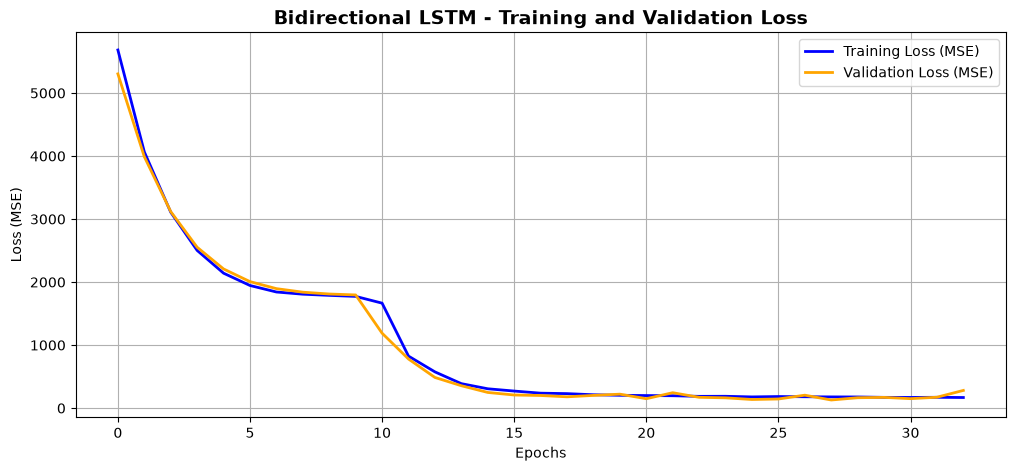

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# رسم خطأ التدريب والتحقق الجديد
plt.plot(
    history.history["loss"],
    label="Training Loss (MSE)",
    linewidth=2,
    color="blue",
)
plt.plot(
    history.history["val_loss"],
    label="Validation Loss (MSE)",
    linewidth=2,
    color="orange",
)

plt.title(
    "Bidirectional LSTM - Training and Validation Loss",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Epochs")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.grid(True)
plt.show()

In [26]:
# استخراج آخر قيمة للـ Loss والـ RMSE للتدريب والتحقق
final_train_loss = history.history["loss"][-1]
final_val_loss = history.history["val_loss"][-1]

final_train_rmse = history.history["rmse"][-1]
final_val_rmse = history.history["val_rmse"][-1]

print(f"Training Loss (MSE): {final_train_loss:.4f}")
print(f"Validation Loss (MSE): {final_val_loss:.4f}")
print("-" * 30)
print(f"Training RMSE: {final_train_rmse:.4f}")
print(f"Validation RMSE: {final_val_rmse:.4f}")

Training Loss (MSE): 168.2655
Validation Loss (MSE): 280.7557
------------------------------
Training RMSE: 12.9717
Validation RMSE: 16.7558


In [27]:
import random
import numpy as np
import pandas as pd

# 1. توليد التنبؤات لكل محركات الاختبار وحفظ الملف النهائي
all_predictions = []
unit_ids = test_data_scaled["unit_number"].unique()

for unit_id in unit_ids:
  engine_df = test_data_scaled[test_data_scaled["unit_number"] == unit_id]
  if len(engine_df) >= sequence_length:
    x_seq = engine_df[feature_cols].values[-sequence_length:]
  else:
    x_seq = np.pad(
        engine_df[feature_cols].values,
        ((sequence_length - len(engine_df), 0), (0, 0)),
        mode="edge",
    )

  pred_rul = model.predict(
      x_seq.reshape(1, sequence_length, len(feature_cols)), verbose=0
  )[0][0]
  all_predictions.append(pred_rul)

# تجميع النتائج في DataFrame نهائي
results_df = pd.DataFrame(
    {
        "Engine_ID": unit_ids,
        "Actual_RUL": true_rul["RUL"].values,
        "Predicted_RUL": all_predictions,
    }
)

# حفظ نسخة محدثة من الملف النهائي للنواتج
output_filename = "Predicted_RUL_Results_BiLSTM.csv"
results_df.to_csv(output_filename, index=False)

# 2. اختيار 20 محركاً بشكل عشوائي وعرضهم في جدول منسق
random_20_engines = results_df.sample(n=20, random_state=None).sort_values(
    by="Engine_ID"
)

# إضافة عمود لحساب نسبة الخطأ المطلق
random_20_engines["Absolute_Error"] = abs(
    random_20_engines["Actual_RUL"] - random_20_engines["Predicted_RUL"]
)

print(
    "=== جدول عشوائي لـ 20 محركاً (بعد تطوير النموذج بـ Bidirectional LSTM"
    " و Rolling Std) ==="
)
display(
    random_20_engines.reset_index(drop=True).style.background_gradient(
        subset=["Absolute_Error"], cmap="Reds"
    )
)

=== جدول عشوائي لـ 20 محركاً (بعد تطوير النموذج بـ Bidirectional LSTM و Rolling Std) ===


,Engine_ID,Actual_RUL,Predicted_RUL,Absolute_Error
0,5,91,112.150620,21.150620
1,6,93,119.613976,26.613976
2,20,16,16.682961,0.682961
3,29,90,97.534042,7.534042
4,32,48,45.556114,2.443886
5,35,11,12.912966,1.912966
6,37,21,26.881556,5.881556
7,45,114,96.731491,17.268509
8,49,21,17.479702,3.520298
9,51,114,87.526848,26.473152


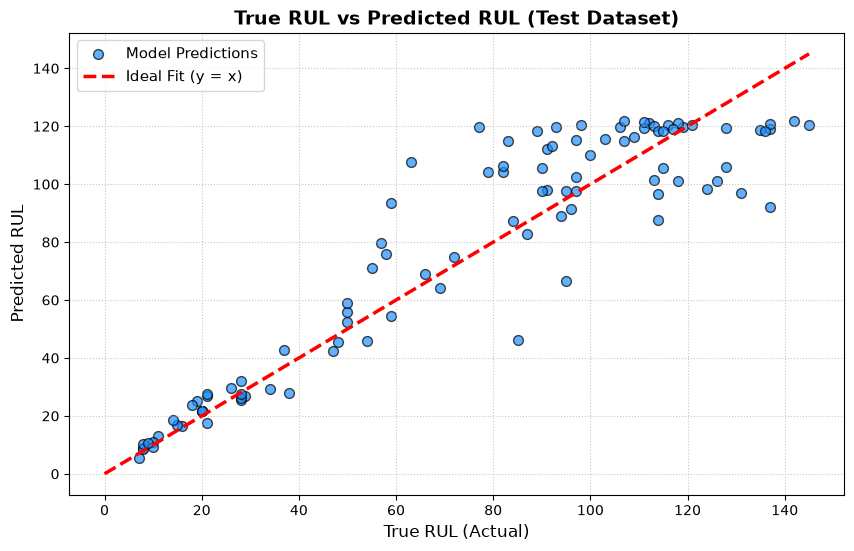

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# رسم نقط التنبؤ مقابل القيم الحقيقية
plt.scatter(
    results_df["Actual_RUL"],
    results_df["Predicted_RUL"],
    color="dodgerblue",
    alpha=0.7,
    edgecolors="k",
    s=50,
    label="Model Predictions",
)

# رسم خط مطابقة مثالي (Ideal Fit Line حيث تكون القيمة المتوقعة مساوية للحقيقية تماماً)
max_val = max(results_df["Actual_RUL"].max(), results_df["Predicted_RUL"].max())
plt.plot(
    [0, max_val],
    [0, max_val],
    color="red",
    linestyle="--",
    linewidth=2.5,
    label="Ideal Fit (y = x)",
)

plt.title("True RUL vs Predicted RUL (Test Dataset)", fontsize=14, fontweight="bold")
plt.xlabel("True RUL (Actual)", fontsize=12)
plt.ylabel("Predicted RUL", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=":", alpha=0.7)
plt.show()

In [29]:
import numpy as np
import pandas as pd

# 1. التأكد من توفر النتائج
if "results_df" not in globals():
  # إذا لم تكن معرفة، نقوم بتحميلها أو توليدها من الملف الحفظ الأخير
  results_df = pd.read_csv("Predicted_RUL_Results_BiLSTM.csv")

# 2. حساب الخطأ المطلق والدقة المئوية لكل محرك
results_df["Absolute_Error"] = abs(
    results_df["Actual_RUL"] - results_df["Predicted_RUL"]
)

# حساب نسبة الدقة: Accuracy = (1 - (Absolute Error / Actual RUL)) * 100
# نستخدم (Actual_RUL + 1) لتفادي القسمة على صفر إذا كان الـ RUL يساوي 0 تماماً
results_df["Accuracy_Percentage"] = (
    1 - (results_df["Absolute_Error"] / (results_df["Actual_RUL"] + 1))
) * 100
results_df["Accuracy_Percentage"] = results_df["Accuracy_Percentage"].clip(
    lower=0
)

# 3. حساب عدد ونسبة المحركات لكل فئة دقة
total_engines = len(results_df)

thresholds = [90, 80, 70, 60]
summary_data = []

for th in thresholds:
  # المحركات التي تحقق دقة أكبر من أو تساوي النسبة
  filtered_df = results_df[results_df["Accuracy_Percentage"] >= th]
  count = len(filtered_df)
  percentage_of_total = (count / total_engines) * 100

  # متوسط فرق الدورات (Error in Cycles) لهذه الفئة
  avg_error_cycles = (
      filtered_df["Absolute_Error"].mean() if count > 0 else 0
  )
  max_error_cycles = filtered_df["Absolute_Error"].max() if count > 0 else 0

  summary_data.append({
      "Accuracy Tier": f">= {th}%",
      "Engine Count": count,
      "Percentage of Test Set": f"{percentage_of_total:.2f}%",
      "Avg Cycle Difference": f"{avg_error_cycles:.2f} cycles",
      "Max Cycle Difference": f"{max_error_cycles:.2f} cycles",
  })

# تحويل النتائج إلى جدول منسق وعرضه
summary_df = pd.DataFrame(summary_data)
print("=== تقرير تفصيلي لنسب الدقة وفروق الدورات للمحركات ===")
display(summary_df.style.set_properties(**{"text-align": "center"}))

=== تقرير تفصيلي لنسب الدقة وفروق الدورات للمحركات ===


,Accuracy Tier,Engine Count,Percentage of Test Set,Avg Cycle Difference,Max Cycle Difference
0,>= 90%,42,42.00%,4.23 cycles,11.39 cycles
1,>= 80%,72,72.00%,7.10 cycles,24.83 cycles
2,>= 70%,86,86.00%,9.28 cycles,33.99 cycles
3,>= 60%,96,96.00%,10.35 cycles,44.71 cycles


In [30]:
import pandas as pd

# 1. التأكد من توفر ملف النتائج أو جدول النتائج
if "results_df" not in globals():
  results_df = pd.read_csv("Predicted_RUL_Results_BiLSTM.csv")

# التأكد من وجود عمود Absolute_Error
if "Absolute_Error" not in results_df.columns:
  results_df["Absolute_Error"] = abs(
      results_df["Actual_RUL"] - results_df["Predicted_RUL"]
  )

# 2. فلترة المحركات التي يزيد فرق الخطأ فيها عن 20 دورة
high_error_engines = results_df[results_df["Absolute_Error"] > 20]

# 3. طباعة النتائج وعرض الجدول
print(f"=== تقرير المحركات ذات الفرق العالي (أكبر من 20 دورة) ===")
print(f"عدد المحركات التي تخطى فيها الفرق 20 دورة: {len(high_error_engines)}")
print(f"نسبتها من إجمالي محركات الاختبار: {(len(high_error_engines) / len(results_df)) * 100:.2f}%")
print("-" * 50)

if len(high_error_engines) > 0:
  display(
      high_error_engines.sort_values(by="Absolute_Error", ascending=False)
      .reset_index(drop=True)
      .style.background_gradient(subset=["Absolute_Error"], cmap="Reds")
  )
else:
  print("ممتاز! لا توجد أي محركات يتجاوز فيها الخطأ 20 دورة.")

=== تقرير المحركات ذات الفرق العالي (أكبر من 20 دورة) ===
عدد المحركات التي تخطى فيها الفرق 20 دورة: 23
نسبتها من إجمالي محركات الاختبار: 23.00%
--------------------------------------------------


,Engine_ID,Actual_RUL,Predicted_RUL,Absolute_Error,Accuracy_Percentage
0,96,137,92.291283,44.708717,67.602379
1,79,63,107.547165,44.547165,30.395055
2,67,77,119.733925,42.733925,45.212917
3,93,85,46.072159,38.927841,54.735068
4,98,59,93.353836,34.353836,42.743607
5,73,131,97.008812,33.991188,74.249100
6,15,83,114.785652,31.785652,62.159938
7,86,89,118.495766,29.495766,67.226927
8,13,95,66.568298,28.431702,70.383644
9,6,93,119.613976,26.613976,71.687260


In [31]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. التأكد من توفر التنبؤات والقياسات الفعلية
if "results_df" not in globals():
  results_df = pd.read_csv("Predicted_RUL_Results_BiLSTM.csv")

actuals = results_df["Actual_RUL"].values
predictions = results_df["Predicted_RUL"].values

# 2. حساب مقاييس الأداء الشاملة
test_rmse = np.sqrt(mean_squared_error(actuals, predictions))
test_mae = mean_absolute_error(actuals, predictions)
r2 = r2_score(actuals, predictions)


# دالة حساب الـ NASA Score الرسمية
def nasa_scoring_function(actual, predicted):
  diff = predicted - actual
  score = 0
  for d in diff:
    if d < 0:
      score += np.exp(-d / 13.0) - 1
    else:
      score += np.exp(d / 10.0) - 1
  return score


nasa_score = nasa_scoring_function(actuals, predictions)

# 3. طباعة تقرير المقاييس الشامل بشكل احترافي
print("=" * 60)
print(" 📈 تقرير مقاييس الأداء النهائية لنموذج Bidirectional LSTM:")
print("=" * 60)
print(f"• Root Mean Squared Error (RMSE) : {test_rmse:.4f}")
print(f"• Mean Absolute Error (MAE)      : {test_mae:.4f}")
print(f"• R² Score (معامل التحديد)        : {r2:.4f}  ({r2*100:.2f}%)")
print(f"• NASA Official Score Function   : {nasa_score:.2f}")
print("=" * 60)

 📈 تقرير مقاييس الأداء النهائية لنموذج Bidirectional LSTM:
• Root Mean Squared Error (RMSE) : 15.9612
• Mean Absolute Error (MAE)      : 11.5394
• R² Score (معامل التحديد)        : 0.8525  (85.25%)
• NASA Official Score Function   : 483.90


In [32]:
import joblib

# حفظ نموذج الـ LSTM
model.save("nasa_rul_lstm_model.keras")

# حفظ الـ Scaler الخاص بتوحيد النطاق
joblib.dump(scaler, "minmax_scaler.pkl")

print("تم حفظ النموذج والـ Scaler بنجاح تام!")

تم حفظ النموذج والـ Scaler بنجاح تام!


In [34]:
import pyodbc
from urllib.parse import quote_plus
from sqlalchemy import create_engine, text

driver = "ODBC Driver 18 for SQL Server"
odbc = (
    f"DRIVER={{{driver}}};SERVER=localhost;DATABASE=EngineRUL;"
    "Trusted_Connection=yes;TrustServerCertificate=yes;"
)
engine = create_engine("mssql+pyodbc:///?odbc_connect=" + quote_plus(odbc))

with engine.connect() as conn:
    print("Connected to:", conn.execute(text("SELECT DB_NAME()")).scalar())

Connected to: EngineRUL


In [35]:
import pandas as pd
from urllib.parse import quote_plus
from sqlalchemy import create_engine, text

# ---- change only this line per notebook ----
DATASET = "FD001"  # FD002 / FD003 / FD004
CSV_PATH = "Predicted_RUL_Results_BiLSTM.csv"
# --------------------------------------------

# 1. Read and validate
df = pd.read_csv(CSV_PATH)
assert {"Engine_ID", "Actual_RUL", "Predicted_RUL"} <= set(
    df.columns
), "Unexpected columns"
assert df["Engine_ID"].is_unique, "Duplicate engine IDs in the CSV"
assert (
    df[["Actual_RUL", "Predicted_RUL"]].notna().all().all()
), "Missing values in the CSV"

df_out = pd.DataFrame(
    {
        "dataset": DATASET,
        "engine_id": df["Engine_ID"].astype(int),
        "actual_rul": df["Actual_RUL"].astype(float),
        "predicted_rul": df["Predicted_RUL"].astype(float),
    }
)

# 2. Connect
odbc = (
    "DRIVER={ODBC Driver 18 for SQL Server};SERVER=localhost;DATABASE=EngineRUL;"
    "Trusted_Connection=yes;TrustServerCertificate=yes;"
)
engine = create_engine("mssql+pyodbc:///?odbc_connect=" + quote_plus(odbc))

# 3. Replace this dataset's rows in ONE transaction (all or nothing)
with engine.begin() as conn:
    conn.execute(
        text("DELETE FROM dbo.rul_predictions WHERE dataset = :ds"),
        {"ds": DATASET},
    )
    df_out.to_sql(
        "rul_predictions", conn, schema="dbo", if_exists="append", index=False
    )

# 4. Verify what is actually in the database
with engine.connect() as conn:
    n = conn.execute(
        text("SELECT COUNT(*) FROM dbo.rul_predictions WHERE dataset = :ds"),
        {"ds": DATASET},
    ).scalar()
print(f"{DATASET}: {len(df_out)} rows sent, {n} rows now in SQL Server")
assert n == len(df_out), "Row count mismatch!"

FD001: 100 rows sent, 100 rows now in SQL Server
